# simulation

Every simulation of the shape-matching experiment, in one notebook. It replaces the Python scripts in `src/`
(adviser, 2026-10-26). Balabit only.

**How to use**

1. Open this notebook with the **`.venv` kernel** (it has numba). VS Code: *Select Kernel* → `.venv`; Jupyter:
   *Kernel → Change kernel*.
2. Edit the **Settings** cell below. Nothing else needs changing.
3. **Run All.** Every section prints what it wrote. Sections switched off in `SECTIONS` are skipped.

**Outputs are CSV files** (plus the figures of sections 9 and 10), under `experiment_earl/runs/<hash>/`. The 6-character `<hash>` is made from
`SETTINGS`, so changing a setting writes to a new folder and never overwrites an earlier result. `runs/` and `cache/`
are git-ignored.

| Section | Writes |
|---|---|
| 3. Batch | `runs/<hash>/<L>_<I>_<sensitivity>_<sessions>/` per run: `config.yaml`, `run.json`, `results/accuracy.csv`, `results/session_progression*.csv`; `runs/batch_log.csv` |
| 4. Accuracy | `runs/<hash>/accuracy.csv` (every run and user), `runs/<hash>/summary/summary.csv` (one row per run) |
| 5. Best per split | `runs/<hash>/best/`: `scores.csv`, `best.csv`, `best_rows.csv` |
| 6. Sensitivity sweep | `runs/<hash>/sweep/`: `confusion.csv`, `user_confusion.csv`, `parts/`, `config.yaml` |
| 7. Matched pairs | `results/matches.csv` of `SINGLE_RUN` |
| 8. Genuine check | `results/genuine_check.csv`, `results/genuine_check_summary.csv` of `SINGLE_RUN` |
| 9. Experiments 1 and 2 | `runs/<hash>/experiments/`: `exp{1,2}_points.csv`, `exp{1,2}_overall.csv`, `exp{1,2}_confusion.csv`, `exp{1,2}.png` |
| 10. Passed strokes | `runs/<hash>/passed_strokes_<window>s/`: `session_results.csv`, `summary.csv`, per `<split>/<user>/`: `trimmed/<session>_points_<window>s.csv`, `first_strokes.csv`, `all_strokes_<window>s.png`, `first_stroke_<window>s.png` |

The default batch (4 splits × 100 sensitivities × 8 session counts = 3,200 runs) takes about 10 minutes on 2 cores. Shrink
`BATCH` to try the notebook out first.

In [1]:
import hashlib
import json
import pickle
import random
import shutil
import subprocess
import time
from dataclasses import dataclass, field
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import yaml

try:
    from numba import njit, prange
except ImportError:
    raise ImportError("numba is not installed in this kernel: choose the .venv kernel, "
                      "or install it here with  %pip install numba") from None

_HERE = Path.cwd()
ROOT = next((p for p in [_HERE, _HERE / "experiment_earl", *_HERE.parents] if (p / "datasets" / "balabit").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No datasets/balabit found from {_HERE}: open this notebook from inside the repository")
RUNS = ROOT / "runs"        # every result, one folder per settings hash
CACHE_DIR = ROOT / "cache"  # DTW results reused across runs (keys hold the settings that change a score)
print("experiment folder:", ROOT)

experiment folder: /home/tin/thesis-mouse-biometrics/experiment_earl


## Settings

Everything the simulation uses. `SETTINGS` names the results folder `runs/<hash>/`; the other blocks say what to run.

In [2]:
SETTINGS = {
    "seed": 945,                # picks the users and each user's session order once (same seed = same draw)
    "dataset_dir": "datasets/balabit/users",              # Balabit, one folder per user (relative to experiment_earl/)
    "labels_file": "datasets/balabit/public_labels.csv",  # sessions with is_illegal = 1 are dropped; None keeps all
    # chunking: cut a session into strokes
    "pause_gap_s": 0.5,         # a pause longer than this many seconds starts a new stroke (clicks also split strokes)
    "min_points": 10,           # strokes with fewer recorded points are dropped as jitter
    "min_length_px": 0,         # strokes with a shorter path (px) are dropped (0 = no filter)
    "resample_n": 64,          # every stroke is redrawn with this many evenly spaced points before matching
    # matching
    "dtw_band": 0.1,            # DTW may stretch a stroke by at most this share of resample_n
    "match_shape_ratio": 0.2,   # a session passes when at least this share of its strokes match
    "match_session_ratio": 0.5, # a user goes through when at least this share of their sessions pass
}

# 3. Batch: every split x sensitivity x sessions is one run, in runs/<hash>/<L>_<I>_<sensitivity>_<sessions>/
BATCH = {
    "splits": [[5, 1], [1, 5], [2, 3], [3, 2]],  # [legitimate, impostor] users, at most 10 together
    "sensitivities": [round(0.01 * i, 2) for i in range(1, 101)],  # strokes match when the DTW distance per point is <= this: 0.01 ... 0.50
    "sessions": list(range(5, 41, 5)),                             # sessions per user: 2, 4, ... 30
    "session_progression": True,  # also count impostors matched per step 1..sessions (off = accuracy only, faster)
}
SKIP_FINISHED_RUNS = True  # a run whose results/accuracy.csv exists is not simulated again

# 6. Sensitivity sweep: per fixed split, one confusion matrix (positive = impostor) per library size and sensitivity
SWEEP = {
    "splits": [[1, 5], [5, 1], [3, 2], [2, 3]],
    "sensitivity": [0.01, 1.00, 0.01],  # start, stop, step of the sensitivities scored
    "sessions_max": 40,                 # library sizes 1, 2, ... up to this many of a legitimate user's first sessions
    "test_sessions": 40,                # tested per user: a legitimate user's last this many, an impostor's first this many
}

# 9. Experiments 1 and 2 (adviser, Thesis Consultation v6). Counts are sessions, positive = impostor:
#    TP = impostor session rejected, FN = let in, TN = legitimate session accepted, FP = wrongly blocked.
EXPERIMENTS = {
    "splits": [[5, 1], [1, 5], [2, 3], [3, 2]],  # [legitimate, impostor] = 1 x 5, 5 x 1, 3 x 2, 2 x 3 (I x L)
    "exp1_sensitivity": [0.01, 1.00, 0.01],      # experiment 1: start, stop, step of the sensitivities, at exp1_sessions
    "exp1_sessions": 1,                          # sessions per user in experiment 1
    "exp2_sessions": [5, 40, 5],                 # experiment 2: start, stop, step of the sessions, at exp 1's best sensitivity
}

# 7-8. One run for the optional checks
SINGLE_RUN = {"n_legitimate": 3, "n_impostor": 7, "sensitivity": 0.02, "sessions_per_user": 10}
GENUINE_HELD_OUT = 2  # genuine check: the legitimate users' next sessions after sessions_per_user (never in a profile)

# 10. Passed strokes: at each split's best setting (needs 5), the sessions that passed, their strokes trimmed and plotted
PASSED_STROKES = {
    "window_s": 0.5,  # keep the first this many seconds of every stroke (0.5 = short strokes)
}

SECTIONS = {
    "batch": True,          # 3. simulate every run of BATCH
    "accuracy": True,       # 4. collect accuracy.csv and summary.csv of every finished run in runs/<hash>/
    "best": True,           # 5. best sensitivity and sessions per split (needs 4)
    "sweep": True,          # 6. sensitivity sweep
    "matches": False,       # 7. matched stroke pairs of SINGLE_RUN
    "genuine_check": False, # 8. own unused sessions of SINGLE_RUN against their own profile
    "experiments": True,    # 9. experiments 1 and 2 with their confusion matrices (missing runs are simulated)
    "passed_strokes": True, # 10. passed sessions at each best setting, strokes trimmed to window_s and plotted (needs 5)
}

## 1. Shared code

Run folders, the Balabit loader, strokes and banded DTW. Nothing to change here.

In [3]:
RUN_KEYS = ("n_legitimate", "n_impostor", "sensitivity", "sessions_per_user")  # name a run inside its hash folder
INVALID_COORDINATE = 65535  # Balabit logging glitch, not a position


def settings_hash(config: dict) -> str:
    """6-character hash of every setting except RUN_KEYS, so runs that differ only in those sit side by side."""
    settings = {k: v for k, v in config.items() if k not in RUN_KEYS}
    return hashlib.sha1(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:6]


def group_folder() -> Path:
    """runs/<hash>/ of SETTINGS: the batch runs, accuracy, best and sweep of these settings."""
    return RUNS / settings_hash(SETTINGS)


def run_folder(config: dict) -> Path:
    name = "_".join(f"{config[k]:.2f}" if k == "sensitivity" else f"{config[k]:g}" for k in RUN_KEYS)
    return RUNS / settings_hash(config) / name


def create_run(folder: Path, config: dict) -> None:
    """Run folder with its settings (config.yaml) and run.json (creation time, git commit)."""
    folder.mkdir(parents=True, exist_ok=True)
    (folder / "config.yaml").write_text(yaml.safe_dump(config, sort_keys=False))
    try:
        commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True,
                                cwd=ROOT, check=True).stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        commit = None
    (folder / "run.json").write_text(json.dumps(
        {"created": datetime.now().isoformat(timespec="seconds"), "git_commit": commit}, indent=2) + "\n")


def write_csv(table: pd.DataFrame, path: Path, index: bool = False) -> None:
    """Write via a temporary file, so an interrupted write never leaves a half file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(".tmp")
    table.to_csv(tmp, index=index)
    tmp.replace(path)


_ILLEGAL: dict = {}


def illegal_sessions(config: dict) -> set[str]:
    """Sessions that labels_file marks is_illegal = 1: recorded by someone else in this user's folder."""
    if not config.get("labels_file"):
        return set()
    if config["labels_file"] not in _ILLEGAL:
        labels = pd.read_csv(ROOT / config["labels_file"])
        _ILLEGAL[config["labels_file"]] = set(labels.loc[labels["is_illegal"] == 1, "filename"])
    return _ILLEGAL[config["labels_file"]]


def list_users(config: dict) -> list[str]:
    return sorted(p.name for p in (ROOT / config["dataset_dir"]).iterdir() if p.is_dir())


def list_sessions(config: dict, user: str) -> list[Path]:
    """Every session of `user` (Balabit's training and test files merged per user, adviser 2026-10-14)."""
    illegal = illegal_sessions(config)
    return sorted(p for p in (ROOT / config["dataset_dir"] / user).iterdir() if p.is_file() and p.name not in illegal)


def session_pool(config: dict, user: str, seed: int) -> list[str]:
    """Session names of `user`, shuffled once from `seed`, so step k+1 contains step k."""
    names = [p.name for p in list_sessions(config, user)]
    random.Random(f"{seed}-{user}").shuffle(names)
    return names


def max_sessions(config: dict) -> int:
    """Largest session count every user can supply."""
    return min(len(list_sessions(config, user)) for user in list_users(config))


def draw_users(config: dict, seed: int) -> tuple[list[str], list[str], dict[str, list[str]]]:
    """One draw from `seed`, fixed for the whole run: legitimate users in draw order, sorted impostors, and each
    user's shuffled session pool."""
    users = list_users(config)
    rng = random.Random(seed)
    legit = rng.sample(users, config["n_legitimate"])
    impostor = sorted(rng.sample([u for u in users if u not in legit], config["n_impostor"]))
    return legit, impostor, {user: session_pool(config, user, seed) for user in legit + impostor}


def load_session(path: Path) -> pd.DataFrame:
    """Columns t (seconds from the first event), x, y, button, state, in time order. Scroll rows and glitch rows
    (x or y = 65535) are dropped; the sort is stable because many Balabit timestamps tie."""
    df = pd.read_csv(path, usecols=["client timestamp", "button", "state", "x", "y"])
    df = df.rename(columns={"client timestamp": "t"}).dropna(subset=["t", "x", "y"])
    df = df[(df["button"] != "Scroll") & (df["x"] < INVALID_COORDINATE) & (df["y"] < INVALID_COORDINATE)]
    df = df.sort_values("t", kind="stable").reset_index(drop=True)
    df["t"] = df["t"] - df["t"].iloc[0] if len(df) else df["t"]
    return df[["t", "x", "y", "button", "state"]]

In [4]:
MOVE, DRAG = 0, 1
KIND_NAMES = {MOVE: "move", DRAG: "drag"}


def path_length(chunk: np.ndarray) -> float:
    return float(np.hypot(*np.diff(chunk[:, :2], axis=0).T).sum())


def segment(df: pd.DataFrame, config: dict) -> list[tuple[np.ndarray, int]]:
    """Strokes as ([x, y, t] array, kind). A new stroke starts after a pause or any click event."""
    click = df["state"].isin(["Pressed", "Released"]).to_numpy()
    clicks_before = np.cumsum(click)
    keep = ~click
    t = df["t"].to_numpy()[keep]
    if not len(t):
        return []
    xyt = np.column_stack([df["x"].to_numpy()[keep], df["y"].to_numpy()[keep], t])
    drag = df["state"].to_numpy()[keep] == "Drag"
    clicked = np.diff(clicks_before[keep], prepend=clicks_before[keep][0]) > 0
    new_chunk = (np.diff(t, prepend=t[0]) > config["pause_gap_s"]) | clicked
    starts = np.flatnonzero(new_chunk)
    starts = np.concatenate([[0], starts[starts > 0], [len(t)]])
    chunks = []
    for lo, hi in zip(starts[:-1], starts[1:]):
        if hi - lo >= config["min_points"] and path_length(xyt[lo:hi]) >= config["min_length_px"]:
            chunks.append((xyt[lo:hi], DRAG if drag[lo:hi].mean() > 0.5 else MOVE))
    return chunks


def normalize(chunk: np.ndarray, n: int) -> np.ndarray | None:
    """Start at the origin, bounding-box diagonal 1, n points evenly spaced by arc length."""
    xy = chunk[:, :2] - chunk[0, :2]
    diag = np.hypot(np.ptp(xy[:, 0]), np.ptp(xy[:, 1]))
    arc = np.concatenate([[0.0], np.cumsum(np.hypot(*np.diff(xy, axis=0).T))])
    if diag == 0 or arc[-1] == 0:
        return None
    grid = np.linspace(0, arc[-1], n)
    return np.column_stack([np.interp(grid, arc, xy[:, 0]), np.interp(grid, arc, xy[:, 1])]) / diag


@dataclass
class Session:
    key: str                      # "<user>/<session>"
    n_chunks: int                 # every recorded stroke, also ones too flat to compare
    paths: dict[int, np.ndarray] = field(default_factory=dict)  # kind -> (m, n, 2) normalized strokes


def segmentation(config: dict) -> tuple:
    """Settings that change which strokes a session has; part of every cache key."""
    return (config["pause_gap_s"], config["min_points"], config["min_length_px"], config["resample_n"])


_SESSIONS: dict = {}  # (session file, segmentation) -> Session, so each file is cut into strokes once


def dataset_session(user: str, name: str, config: dict) -> Session:
    path = ROOT / config["dataset_dir"] / user / name
    if (path, segmentation(config)) not in _SESSIONS:
        chunks = segment(load_session(path), config)
        session = Session(f"{user}/{name}", len(chunks))
        for kind in (MOVE, DRAG):
            paths = [normalize(c, config["resample_n"]) for c, k in chunks if k == kind]
            session.paths[kind] = np.array([p for p in paths if p is not None]).reshape(-1, config["resample_n"], 2)
        _SESSIONS[(path, segmentation(config))] = session
    return _SESSIONS[(path, segmentation(config))]


@njit(cache=True)
def _dtw_within(a, b, band, cap, prev, cur):
    """True if the banded DTW cost between paths a and b is at most `cap` (gives up once every cell exceeds it)."""
    n = a.shape[0]
    prev[:] = np.inf
    prev[0] = 0.0
    for i in range(n):
        cur[:] = np.inf
        row_min = np.inf
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            dx, dy = a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]
            value = np.sqrt(dx * dx + dy * dy) + min(prev[j], prev[j + 1], cur[j])
            cur[j + 1] = value
            row_min = min(row_min, value)
        if row_min > cap:
            return False
        prev, cur = cur, prev
    return prev[n] <= cap


@njit(parallel=True, cache=True)
def has_match(queries, library, band, cap):
    """Per query path: does any library path lie within DTW cost `cap`?"""
    n = queries.shape[1]
    found = np.zeros(queries.shape[0], dtype=np.bool_)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            if _dtw_within(queries[q], library[k], band, cap, prev, cur):
                found[q] = True
                break
    return found


@njit(cache=True)
def _dtw_cost(a, b, band, cap, prev, cur):
    """Banded DTW cost between paths a and b, or inf once every cell exceeds `cap`."""
    n = a.shape[0]
    prev[:] = np.inf
    prev[0] = 0.0
    for i in range(n):
        cur[:] = np.inf
        row_min = np.inf
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            dx, dy = a[i, 0] - b[j, 0], a[i, 1] - b[j, 1]
            value = np.sqrt(dx * dx + dy * dy) + min(prev[j], prev[j + 1], cur[j])
            cur[j + 1] = value
            row_min = min(row_min, value)
        if row_min > cap:
            return np.inf
        prev, cur = cur, prev
    return prev[n]


@njit(parallel=True, cache=True)
def best_distance(queries, library, band, cap):
    """Per query path: smallest DTW cost to any library path (inf if none is within `cap`)."""
    n = queries.shape[1]
    best = np.full(queries.shape[0], np.inf)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            cost = _dtw_cost(queries[q], library[k], band, min(cap, best[q]), prev, cur)
            if cost < best[q]:
                best[q] = cost
    return best


COSTS_PATH = CACHE_DIR / "costs.pkl"
_COSTS: dict = {}  # (query session, library session, segmentation, band) -> {kind: smallest DTW cost per query stroke}
if COSTS_PATH.exists():
    _COSTS.update(pickle.loads(COSTS_PATH.read_bytes()))
_SAVED = {"pairs": len(_COSTS), "time": time.monotonic()}


def pair_costs(query: Session, library: Session, config: dict) -> dict[int, np.ndarray]:
    """Smallest DTW cost of every query stroke to the library session's strokes of the same kind. It does not depend on
    the sensitivity, so it is computed once and reused for every sensitivity (kept in RAM and in cache/costs.pkl)."""
    n = config["resample_n"]
    key = (query.key, library.key, segmentation(config), config["dtw_band"])
    if key not in _COSTS:
        band = int(round(config["dtw_band"] * n))
        _COSTS[key] = {kind: best_distance(paths, library.paths[kind], band, np.inf)
                       if len(paths) and len(library.paths[kind]) else np.full(len(paths), np.inf)
                       for kind, paths in query.paths.items()}
    return _COSTS[key]


def pair_matches(query: Session, library: Session, config: dict) -> dict[int, np.ndarray]:
    """Per query stroke: does a library stroke lie within DTW cost sensitivity * resample_n (the has_match rule)?"""
    cap = config["sensitivity"] * config["resample_n"]
    return {kind: costs <= cap for kind, costs in pair_costs(query, library, config).items()}


def matched_chunks(query: Session, library: list[Session], config: dict) -> int:
    """Strokes of `query` (same kind only) that match a stroke in any library session."""
    total = 0
    for kind, paths in query.paths.items():
        found = np.zeros(len(paths), dtype=bool)
        for session in library:
            found |= pair_matches(query, session, config)[kind]
        total += int(found.sum())
    return total


def save_costs(force: bool = False) -> None:
    """Write new DTW costs to cache/costs.pkl (at most every 10 minutes unless forced), so a restart reuses them."""
    if len(_COSTS) == _SAVED["pairs"] or not (force or time.monotonic() - _SAVED["time"] > 600):
        return
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    tmp = COSTS_PATH.with_suffix(".tmp")
    with tmp.open("wb") as handle:
        pickle.dump(_COSTS, handle, protocol=pickle.HIGHEST_PROTOCOL)
    tmp.replace(COSTS_PATH)
    _SAVED.update(pairs=len(_COSTS), time=time.monotonic())


print(f"{len(_COSTS):,} cached DTW session pairs loaded")

35,200 cached DTW session pairs loaded


## 2. Data check

Users and sessions available, and whether the settings fit them.

In [5]:
users = list_users(SETTINGS)
fewest = max_sessions(SETTINGS)
total = sum(len(list_sessions(SETTINGS, u)) for u in users)
print(f"{len(users)} users, {total:,} sessions; every user has at least {fewest}")

problems = [f"split {split} needs {sum(split)} users; the data has {len(users)}"
            for split in BATCH["splits"] + SWEEP["splits"] + [[SINGLE_RUN["n_legitimate"], SINGLE_RUN["n_impostor"]]]
            if sum(split) > len(users)]
if 2 * max(BATCH["sessions"]) > fewest:
    problems.append(f"BATCH sessions up to {max(BATCH['sessions'])}: a legitimate user's last sessions would overlap "
                    f"the profile (at most {fewest // 2})")
if SWEEP["sessions_max"] + SWEEP["test_sessions"] > fewest:
    problems.append(f"SWEEP sessions_max + test_sessions = {SWEEP['sessions_max'] + SWEEP['test_sessions']} > {fewest}")
if SINGLE_RUN["sessions_per_user"] + GENUINE_HELD_OUT > fewest:
    problems.append(f"SINGLE_RUN sessions_per_user + GENUINE_HELD_OUT > {fewest}")
if problems:
    raise ValueError("Settings do not fit the data:\n- " + "\n- ".join(problems))
print("results folder:", group_folder())

10 users, 1,271 sessions; every user has at least 87
results folder: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f


## 3. Batch: simulate every run

For each run (split, sensitivity, sessions per user), one draw from `seed` fixes the legitimate users, the impostors
and every user's session order.

- **Accuracy** (`results/accuracy.csv`, one row per user): a legitimate user's own **last** `sessions` sessions (never
  in a profile) against their own profile; an impostor's **first** `sessions` sessions against the legitimate profile
  that passes most of them. A session passes when at least `match_shape_ratio` of its strokes match; a user goes
  through when at least `match_session_ratio` of their sessions pass.
- **Session progression** (`results/session_progression*.csv`, if `BATCH["session_progression"]`): for 1, 2, ...
  `sessions` sessions per user and the first 1, 2, ... legitimate users, which impostors match a profile.

Each session pair's DTW cost is computed once and reused by every run and sensitivity (`cache/costs.pkl`). The
session progression is computed once per sensitivity and split, for the largest `sessions`, and the shorter runs
take their steps from it.

In [6]:
def step_ratios(legit: list[str], impostor: list[str], order: dict, top: int, config: dict) -> dict:
    """(impostor, profile) -> (top, top) array: the share of strokes of the impostor's session i that match the
    profile's first k sessions, at row i, column k - 1. Library sessions are added one at a time, so every step
    1..top comes from one pass (the same count as matched_chunks)."""
    ratios = {}
    for user in impostor:
        sessions = [dataset_session(user, name, config) for name in order[user][:top]]
        for profile in legit:
            library = [dataset_session(profile, name, config) for name in order[profile][:top]]
            table = np.zeros((top, top))
            for i, session in enumerate(sessions):
                found = {kind: np.zeros(len(paths), dtype=bool) for kind, paths in session.paths.items()}
                for j, lib in enumerate(library):
                    for kind, matches in pair_matches(session, lib, config).items():
                        found[kind] |= matches
                    table[i, j] = sum(int(f.sum()) for f in found.values()) / max(session.n_chunks, 1)
            ratios[user, profile] = table
    return ratios


def run_step(legit: list[str], impostor: list[str], k: int, ratios: dict, config: dict) -> list[dict]:
    """Each impostor's first k sessions against each legitimate profile (first k sessions); matched when any single
    profile passes at least match_session_ratio of them."""
    rows = []
    for user in impostor:
        per_profile = {p: list(ratios[user, p][:k, k - 1]) for p in legit}
        share = {p: float(np.mean([r >= config["match_shape_ratio"] for r in ratios])) for p, ratios in per_profile.items()}
        best = max(per_profile, key=lambda p: (share[p], np.mean(per_profile[p])))
        rows.append({
            "sessions": k, "impostor": user, "best_profile": best,
            "mean_chunk_ratio": round(float(np.mean(per_profile[best])), 3),
            "sessions_matched": f"{round(share[best] * k)}/{k}",
            "matched": share[best] >= config["match_session_ratio"],
            "matched_by": ",".join(p for p, v in share.items() if v >= config["match_session_ratio"]),
        })
    return rows


_RATIOS: dict = {}  # (settings hash, sensitivity, legitimate, impostors) -> step_ratios of the largest session count


def progression(config: dict, legit: list[str], impostor: list[str], order: dict) -> dict[str, pd.DataFrame]:
    """Every step 1..sessions_per_user with the first 1..n_legitimate legitimate users. The stroke ratios are computed
    once per sensitivity and split, for the largest session count of BATCH, and reused by the shorter runs."""
    key = (settings_hash(config), config["sensitivity"], tuple(legit), tuple(impostor))
    if key not in _RATIOS:
        _RATIOS.clear()  # the batch runs come grouped by sensitivity and split: keep one in memory
        top = max([config["sessions_per_user"], *BATCH["sessions"]])
        _RATIOS[key] = step_ratios(legit, impostor, order, top, config)
    steps = pd.DataFrame([{"legit_users": n, "legitimate": ",".join(legit[:n]), **row}
                          for k in range(1, config["sessions_per_user"] + 1)
                          for n in range(1, len(legit) + 1)
                          for row in run_step(legit[:n], impostor, k, _RATIOS[key], config)])
    per_step = (steps.groupby(["legit_users", "sessions"])["matched"]
                .agg(matched_detected="sum", sensitivity="mean").reset_index())
    summary = per_step[per_step["legit_users"] == len(legit)].set_index("sessions")[["matched_detected", "sensitivity"]]
    summary["n_legit"], summary["n_impostor"], summary["seed"] = len(legit), len(impostor), config["seed"]
    heatmap = per_step.pivot(index="sessions", columns="legit_users", values="sensitivity")
    full = steps[steps["legit_users"] == len(legit)]
    per_user = pd.DataFrame([{"profile": p, "sessions": r.sessions, "impostor": r.impostor,
                              "matched": p in r.matched_by.split(",")} for r in full.itertuples() for p in legit])
    per_user = per_user.groupby(["profile", "sessions"], sort=False)["matched"].sum().rename("impostors_matched").reset_index()
    return {"session_progression_steps": steps, "session_progression": summary.round(3),
            "session_progression_heatmap": heatmap.round(3), "session_progression_users": per_user}


def score(user: str, sessions: list[str], library: list[Session], config: dict) -> dict:
    """Sessions of `user` that pass (>= match_shape_ratio of their strokes match the library), plus the strokes."""
    passed = matched = strokes = 0
    for name in sessions:
        session = dataset_session(user, name, config)
        hits = matched_chunks(session, library, config)
        passed += hits / max(session.n_chunks, 1) >= config["match_shape_ratio"]
        matched += hits
        strokes += session.n_chunks
    return {"passed": passed, "tested": len(sessions), "matched_strokes": matched, "strokes": strokes}


def accuracy_rows(config: dict, name: str, legit: list[str], impostor: list[str], order: dict) -> list[dict]:
    """Legitimate: own last sessions_per_user sessions (never in a profile) against own profile. Impostor: first
    sessions_per_user sessions against the legitimate profile that passes most of them."""
    k = config["sessions_per_user"]
    libraries = {u: [dataset_session(u, n, config) for n in order[u][:k]] for u in legit}
    run = {"run": name, "sensitivity": config["sensitivity"], "sessions": k,
           "n_legitimate": config["n_legitimate"], "n_impostor": config["n_impostor"]}
    rows = [{**run, "kind": "legitimate", "user": u, "profile": u, **score(u, order[u][-k:], libraries[u], config)}
            for u in legit]
    for user in impostor:
        scores = {p: score(user, order[user][:k], lib, config) for p, lib in libraries.items()}
        profile = max(scores, key=lambda p: (scores[p]["passed"], scores[p]["matched_strokes"] / max(scores[p]["strokes"], 1)))
        rows.append({**run, "kind": "impostor", "user": user, "profile": profile, **scores[profile]})
    for row in rows:
        row["through"] = row["passed"] >= config["match_session_ratio"] * row["tested"]
    return rows


def run_done(folder: Path) -> bool:
    results = folder / "results"
    return (results / "accuracy.csv").exists() and (
        not BATCH["session_progression"] or (results / "session_progression.csv").exists())


def simulate(config: dict) -> None:
    """One run: its folder, then the session progression and accuracy CSVs (accuracy last: it marks the run done)."""
    folder = run_folder(config)
    if not (folder / "config.yaml").exists():
        create_run(folder, config)
    legit, impostor, order = draw_users(config, config["seed"])
    results = folder / "results"
    if BATCH["session_progression"]:
        for name, table in progression(config, legit, impostor, order).items():
            write_csv(table, results / f"{name}.csv", index=name in ("session_progression", "session_progression_heatmap"))
    write_csv(pd.DataFrame(accuracy_rows(config, folder.name, legit, impostor, order)), results / "accuracy.csv")


def log_run(row: dict) -> None:
    log = RUNS / "batch_log.csv"
    pd.DataFrame([row]).to_csv(log, mode="a", header=not log.exists(), index=False)


if SECTIONS["batch"]:
    plan = [{**SETTINGS, "n_legitimate": legit_n, "n_impostor": impostor_n, "sensitivity": sens, "sessions_per_user": k}
            for sens in BATCH["sensitivities"] for legit_n, impostor_n in BATCH["splits"] for k in BATCH["sessions"]]
    todo = [c for c in plan if not (SKIP_FINISHED_RUNS and run_done(run_folder(c)))]
    print(f"{len(plan):,} runs in the plan, {len(plan) - len(todo):,} finished earlier, {len(todo):,} to run")
    counts = {"ok": 0, "failed": 0}
    for i, config in enumerate(todo, 1):
        name = run_folder(config).relative_to(RUNS).as_posix()
        start = time.monotonic()
        try:
            simulate(config)
            status, error = "ok", ""
        except Exception as exc:  # log it and go on with the next run
            status, error = "failed", f"{type(exc).__name__}: {exc}"
        seconds = round(time.monotonic() - start)
        counts[status] += 1
        print(f"[{i}/{len(todo)}] {name} ... {status} ({seconds // 60}m {seconds % 60:02d}s){'  ' + error if error else ''}",
              flush=True)
        log_run({"time": datetime.now().isoformat(timespec="seconds"), "run": name, "status": status,
                 "seconds": seconds, "error": error})
        save_costs()
        if i == len(todo) or todo[i]["sensitivity"] != config["sensitivity"]:
            save_costs(force=True)
    save_costs(force=True)
    print(f"Batch: {counts['ok']} ok, {counts['failed']} failed. Log: {RUNS / 'batch_log.csv'}")

3,200 runs in the plan, 0 finished earlier, 3,200 to run


[1/3200] 19399f/5_1_0.01_5 ... ok (1m 06s)


[2/3200] 19399f/5_1_0.01_10 ... ok (0m 02s)


[3/3200] 19399f/5_1_0.01_15 ... ok (0m 04s)


[4/3200] 19399f/5_1_0.01_20 ... ok (0m 06s)


...

[3197/3200] 19399f/3_2_1.00_25 ... ok (0m 00s)


[3198/3200] 19399f/3_2_1.00_30 ... ok (0m 00s)


[3199/3200] 19399f/3_2_1.00_35 ... ok (0m 00s)


[3200/3200] 19399f/3_2_1.00_40 ... ok (0m 00s)


Batch: 3200 ok, 0 failed. Log: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/batch_log.csv


## 4. Accuracy of every run

Collects `results/accuracy.csv` of every finished run in `runs/<hash>/` (also runs from earlier batches with the same
settings) into one table, and one summary row per run.

In [7]:
def summarize(table: pd.DataFrame) -> pd.DataFrame:
    """One row per run: legitimate sessions passed and users accepted, impostor sessions passed and users through."""
    rows = []
    for (run, n_legit, n_impostor, sens, sessions), part in table.groupby(
            ["run", "n_legitimate", "n_impostor", "sensitivity", "sessions"]):
        legit, impostor = part[part.kind == "legitimate"], part[part.kind == "impostor"]
        rows.append({"split": f"{n_legit}_{n_impostor}", "n_legitimate": n_legit, "n_impostor": n_impostor,
                     "sensitivity": sens, "sessions": sessions, "run": run,
                     "legit_passed": int(legit.passed.sum()), "legit_tested": int(legit.tested.sum()),
                     "legit_accepted": f"{int(legit.through.sum())}/{len(legit)}",
                     "impostor_passed": int(impostor.passed.sum()), "impostor_tested": int(impostor.tested.sum()),
                     "impostors_through": f"{int(impostor.through.sum())}/{len(impostor)}"})
    return pd.DataFrame(rows).sort_values(["n_legitimate", "sensitivity", "sessions"])


if SECTIONS["accuracy"]:
    group = group_folder()
    parts = [pd.read_csv(p) for p in sorted(group.glob("*/results/accuracy.csv"))]
    if not parts:
        print(f"No finished runs in {group}: run section 3 first")
    else:
        accuracy = pd.concat(parts, ignore_index=True).sort_values(
            ["n_legitimate", "n_impostor", "sensitivity", "sessions"], kind="stable")
        write_csv(accuracy, group / "accuracy.csv")
        write_csv(summarize(accuracy), group / "summary" / "summary.csv")
        print(f"{len(parts):,} runs, {len(accuracy):,} user rows")
        print(f"Output: {group / 'accuracy.csv'}, {group / 'summary' / 'summary.csv'}")

3,660 runs, 20,400 user rows
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/accuracy.csv, /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/summary/summary.csv


## 5. Best sensitivity and sessions per split

Every (split, sensitivity, sessions) cell scored as (legitimate accepted + impostors rejected) / 2, so 0.5 = chance:
**user accuracy** counts users through and ranks the cells; **session accuracy** counts sessions and breaks ties
(then fewer sessions, then lower sensitivity). Chosen on the same runs it scores, so the best value is optimistic.

In [8]:
CELL = ["n_legitimate", "n_impostor", "sensitivity", "sessions"]
SPLIT = ["n_legitimate", "n_impostor"]


def score_cells(table: pd.DataFrame) -> pd.DataFrame:
    sums = table.groupby(CELL + ["kind"]).agg(passed=("passed", "sum"), tested=("tested", "sum"),
                                              through=("through", "sum"), users=("user", "size")).unstack("kind")
    cells = pd.DataFrame({
        "legit_accepted": sums["passed"]["legitimate"] / sums["tested"]["legitimate"],
        "impostor_accepted": sums["passed"]["impostor"] / sums["tested"]["impostor"],
        "legit_through": sums["through"]["legitimate"], "legit_users": sums["users"]["legitimate"],
        "impostor_through": sums["through"]["impostor"], "impostor_users": sums["users"]["impostor"],
    })
    cells["user_accuracy"] = (cells["legit_through"] / cells["legit_users"]
                              + 1 - cells["impostor_through"] / cells["impostor_users"]) / 2
    cells["session_accuracy"] = (cells["legit_accepted"] + 1 - cells["impostor_accepted"]) / 2
    return cells.reset_index()


def pick_best(cells: pd.DataFrame) -> pd.DataFrame:
    ranked = cells.sort_values(SPLIT + ["user_accuracy", "session_accuracy", "sessions", "sensitivity"],
                               ascending=[True, True, False, False, True, True])
    best = ranked.groupby(SPLIT, as_index=False).head(1).reset_index(drop=True)
    best["beats_chance"] = best["user_accuracy"] > 0.5
    return best


if SECTIONS["best"]:
    group = group_folder()
    if not (group / "accuracy.csv").exists():
        print(f"No {group / 'accuracy.csv'}: run section 4 first")
    else:
        table = pd.read_csv(group / "accuracy.csv")
        cells = score_cells(table)
        best = pick_best(cells)
        out = group / "best"
        if out.exists():
            shutil.rmtree(out)
        write_csv(cells, out / "scores.csv")
        write_csv(best, out / "best.csv")
        write_csv(best[CELL].merge(table, on=CELL), out / "best_rows.csv")
        print(best[SPLIT + ["sensitivity", "sessions", "user_accuracy", "session_accuracy", "beats_chance"]]
              .round(3).to_string(index=False))
        print(f"Output: {out}/ (scores.csv, best.csv, best_rows.csv)")

 n_legitimate  n_impostor  sensitivity  sessions  user_accuracy  session_accuracy  beats_chance
            1           5         0.05         1          1.000             1.000          True
            1           9         0.03         8          0.889             0.785          True
            2           3         0.05         1          0.750             0.750          True
            3           2         0.05         1          0.667             0.667          True
            5           1         0.02        25          0.800             0.596          True
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/best/ (scores.csv, best.csv, best_rows.csv)


## 6. Sensitivity sweep

For each fixed split of `SWEEP` (only the users are drawn from `seed`), every library size 1 … `sessions_max` and
every sensitivity: each test session is accepted or rejected, giving TP / FP / FN / TN with positive = impostor.
A legitimate user's last `test_sessions` sessions are tested against their own library; an impostor's first
`test_sessions` against each legitimate library as a separate attempt. DTW costs are computed once per session
pair and shared with the batch (`cache/costs.pkl`); each sensitivity is a cut on them. Finished splits are kept in `parts/` and
reused while `SWEEP` and `SETTINGS` stay the same.

In [9]:
def pair_distance(query: Session, library: Session, config: dict) -> dict[int, np.ndarray]:
    """Best per-point DTW distance of every query stroke to the library session's strokes of the same kind: the batch's
    pair_costs divided by resample_n, so the sweep and the batch share one DTW cache (cache/costs.pkl)."""
    return {kind: costs / config["resample_n"] for kind, costs in pair_costs(query, library, config).items()}


def session_curve(query: Session, library: list[Session], config: dict) -> np.ndarray:
    """(strokes, k) best distance of each query stroke to the first 1..k library sessions (running minimum)."""
    columns = [np.concatenate([pair_distance(query, lib, config)[kind] for kind in query.paths]) for lib in library]
    return np.minimum.accumulate(np.stack(columns, axis=1), axis=1)


def accepted(curve: np.ndarray, n_chunks: int, sensitivities: np.ndarray, ratio: float) -> np.ndarray:
    """(k, sensitivity) bool: does the session pass a k-session library at each sensitivity?"""
    matched = (curve[:, :, None] <= sensitivities[None, None, :]).sum(axis=0)
    return matched / max(n_chunks, 1) >= ratio


def sweep_split(legit_n: int, impostor_n: int, sens: np.ndarray) -> tuple[pd.DataFrame, pd.DataFrame]:
    """One row per (sessions, sensitivity) with TP/FP/FN/TN over test sessions and over users."""
    config = {**SETTINGS, "n_legitimate": legit_n, "n_impostor": impostor_n}
    legit, impostor, order = draw_users(config, config["seed"])
    m, t = SWEEP["sessions_max"], SWEEP["test_sessions"]
    ratio, through = config["match_shape_ratio"], config["match_session_ratio"]
    libraries = {u: [dataset_session(u, s, config) for s in order[u][:m]] for u in legit}

    def verdicts(user: str, tests: list[str], profiles: list[str]) -> np.ndarray:
        """(sessions tested x profiles, k, sensitivity): one attempt per (session, profile) pair."""
        out = []
        for name in tests:
            query = dataset_session(user, name, config)
            out.extend(accepted(session_curve(query, libraries[p], config), query.n_chunks, sens, ratio)
                       for p in profiles)
        return np.array(out)

    legit_acc = {u: verdicts(u, order[u][-t:], [u]) for u in legit}
    impostor_acc = {u: verdicts(u, order[u][:t], legit) for u in impostor}
    attempts = impostor_n * t * legit_n  # impostor (session, profile) pairs
    tn = sum(a.sum(axis=0) for a in legit_acc.values())
    fn = sum(a.sum(axis=0) for a in impostor_acc.values())
    users_tn = sum(a.mean(axis=0) >= through for a in legit_acc.values())
    users_fn = sum(a.mean(axis=0) >= through for a in impostor_acc.values())

    k, s = np.meshgrid(np.arange(1, m + 1), sens, indexing="ij")
    table = pd.DataFrame({"n_legitimate": legit_n, "n_impostor": impostor_n, "sessions": k.ravel(), "sensitivity": s.ravel(),
                          "TP": (attempts - fn).ravel(), "FP": (legit_n * t - tn).ravel(),
                          "FN": fn.ravel(), "TN": tn.ravel(),
                          "users_TP": (impostor_n - users_fn).ravel(), "users_FP": (legit_n - users_tn).ravel(),
                          "users_FN": users_fn.ravel(), "users_TN": users_tn.ravel()})
    table["accuracy"] = (table["TP"] + table["TN"]) / (attempts + legit_n * t)
    table["FAR"] = table["FN"] / attempts            # impostor attempts let in
    table["FRR"] = table["FP"] / (legit_n * t)      # legitimate sessions rejected
    table["balanced_accuracy"] = 1 - (table["FAR"] + table["FRR"]) / 2
    table["users_accuracy"] = (table["users_TP"] + table["users_TN"]) / (legit_n + impostor_n)
    table["legitimate"] = ",".join(legit)
    table["impostor"] = ",".join(impostor)
    return table, user_table(legit_n, impostor_n, legit, legit_acc, impostor_acc, k, s)


def user_table(legit_n: int, impostor_n: int, legit: list[str], legit_acc: dict, impostor_acc: dict,
               k: np.ndarray, s: np.ndarray) -> pd.DataFrame:
    """One confusion matrix per (legitimate user, half, sessions, sensitivity): the user's own test sessions and every
    impostor attempt against the user's library. Test sessions alternate between halves (even = pick, odd = check),
    so section 7 can choose a setting on one half and score it on sessions it never saw."""
    rows = []
    for p, u in enumerate(legit):
        genuine = legit_acc[u]
        attacks = np.concatenate([a[p::legit_n] for a in impostor_acc.values()])  # attempts are (session, profile)
        for half, start in (("pick", 0), ("check", 1)):
            g, a = genuine[start::2], attacks[start::2]
            tn, fn = g.sum(axis=0), a.sum(axis=0)
            rows.append(pd.DataFrame({"n_legitimate": legit_n, "n_impostor": impostor_n, "user": u, "half": half,
                                      "sessions": k.ravel(), "sensitivity": s.ravel(),
                                      "TP": (len(a) - fn).ravel(), "FP": (len(g) - tn).ravel(),
                                      "FN": fn.ravel(), "TN": tn.ravel()}))
    table = pd.concat(rows, ignore_index=True)
    table["FAR"] = table["FN"] / (table["TP"] + table["FN"])
    table["FRR"] = table["FP"] / (table["FP"] + table["TN"])
    table["balanced_accuracy"] = 1 - (table["FAR"] + table["FRR"]) / 2
    return table


if SECTIONS["sweep"]:
    start, stop, step = SWEEP["sensitivity"]
    sens = np.round(np.arange(start, stop + step / 2, step), 4)
    folder = group_folder() / "sweep"
    plan_text = yaml.safe_dump({**SETTINGS, "sweep": SWEEP}, sort_keys=False)
    if (folder / "config.yaml").exists() and (folder / "config.yaml").read_text() != plan_text:
        shutil.rmtree(folder / "parts", ignore_errors=True)  # SWEEP changed: earlier splits no longer apply
    (folder / "parts").mkdir(parents=True, exist_ok=True)
    (folder / "config.yaml").write_text(plan_text)
    parts, users = [], []
    for legit_n, impostor_n in SWEEP["splits"]:
        path = folder / "parts" / f"{legit_n}_{impostor_n}.csv"
        user_path = folder / "parts" / f"{legit_n}_{impostor_n}_users.csv"
        if path.exists() and user_path.exists():
            parts.append(pd.read_csv(path))
            users.append(pd.read_csv(user_path))
            print(f"[{legit_n} L, {impostor_n} I] finished earlier, reused")
            continue
        start_time = time.monotonic()
        part, user_part = sweep_split(legit_n, impostor_n, sens)
        save_costs(force=True)
        write_csv(part, path)
        write_csv(user_part, user_path)
        parts.append(part)
        users.append(user_part)
        print(f"[{legit_n} L, {impostor_n} I] done ({time.monotonic() - start_time:.0f} s)", flush=True)
    write_csv(pd.concat(parts), folder / "confusion.csv")
    write_csv(pd.concat(users), folder / "user_confusion.csv")
    print(f"{len(SWEEP['splits'])} splits x {SWEEP['sessions_max']} sessions x {len(sens)} sensitivities "
          f"= {sum(len(p) for p in parts):,} confusion matrices")
    print(f"Output: {folder}/ (confusion.csv, user_confusion.csv, parts/, config.yaml)")

[1 L, 5 I] finished earlier, reused
[5 L, 1 I] finished earlier, reused


[3 L, 2 I] finished earlier, reused
[2 L, 3 I] finished earlier, reused


4 splits x 40 sessions x 100 sensitivities = 16,000 confusion matrices
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/sweep/ (confusion.csv, user_confusion.csv, parts/, config.yaml)


## 7. Matched stroke pairs (optional)

For `SINGLE_RUN`: per legitimate user and session step k, every impostor stroke (first k sessions) that matches a
stroke in the user's first k sessions, with the first matching stroke and its DTW cost per point. The printed verdict
per impostor uses the same rules as the batch.

In [10]:
@njit(parallel=True, cache=True)
def first_match(queries, library, band, cap):
    """Per query path: index of the first library path within DTW cost `cap`, or -1 (same search as has_match)."""
    n = queries.shape[1]
    found = np.full(queries.shape[0], -1, dtype=np.int64)
    for q in prange(queries.shape[0]):
        prev, cur = np.empty(n + 1), np.empty(n + 1)
        for k in range(library.shape[0]):
            if _dtw_within(queries[q], library[k], band, cap, prev, cur):
                found[q] = k
                break
    return found


@njit(cache=True)
def dtw_cost(a, b, band):
    """Full banded DTW cost between paths a and b."""
    n = a.shape[0]
    cost = np.full((n + 1, n + 1), np.inf)
    cost[0, 0] = 0.0
    for i in range(n):
        for j in range(max(0, i - band), min(n - 1, i + band) + 1):
            d = np.sqrt((a[i, 0] - b[j, 0]) ** 2 + (a[i, 1] - b[j, 1]) ** 2)
            cost[i + 1, j + 1] = d + min(cost[i, j], cost[i, j + 1], cost[i + 1, j])
    return cost[n, n]


def step_matches(profile: str, impostor: list[str], order: dict, k: int, config: dict, pairs: dict) -> list[dict]:
    """Every impostor stroke (first k sessions) with a matching stroke in the profile's first k sessions."""
    n = config["resample_n"]
    band, cap = int(round(config["dtw_band"] * n)), config["sensitivity"] * n
    library = [dataset_session(profile, name, config) for name in order[profile][:k]]
    rows = []
    for user in impostor:
        for name in order[user][:k]:
            query = dataset_session(user, name, config)
            for kind, paths in query.paths.items():
                best = np.full(len(paths), -1)
                source = np.full(len(paths), -1)
                for j, lib in enumerate(library):
                    key = (query.key, lib.key, kind)
                    if key not in pairs:
                        pairs[key] = first_match(paths, lib.paths[kind], band, cap) if len(lib.paths[kind]) and len(paths) \
                            else np.full(len(paths), -1)
                    new = (best < 0) & (pairs[key] >= 0)
                    best[new], source[new] = pairs[key][new], j
                for q in np.flatnonzero(best >= 0):
                    lib = library[source[q]]
                    rows.append({"profile": profile, "sessions": k, "impostor": user, "impostor_session": name,
                                 "kind": KIND_NAMES[kind], "chunk": int(q), "profile_session": lib.key.split("/")[-1],
                                 "profile_chunk": int(best[q]),
                                 "cost_per_point": dtw_cost(paths[q], lib.paths[kind][best[q]], band) / n})
    return rows


def session_verdicts(rows: list[dict], impostor: list[str], order: dict, k: int, config: dict) -> list[str]:
    """Per impostor: matched strokes and sessions at the batch's matching rules."""
    lines = []
    for user in impostor:
        ratios, strokes, matched = [], 0, 0
        for name in order[user][:k]:
            session = dataset_session(user, name, config)
            hits = sum(r["impostor"] == user and r["impostor_session"] == name for r in rows)
            ratios.append(hits / max(session.n_chunks, 1))
            strokes += session.n_chunks
            matched += hits
        hit_sessions = sum(r >= config["match_shape_ratio"] for r in ratios)
        verdict = "MATCHED" if hit_sessions / len(ratios) >= config["match_session_ratio"] else "not matched"
        lines.append(f"{user}: {matched:,}/{strokes:,} strokes match, {hit_sessions}/{len(ratios)} sessions "
                     f"≥ {config['match_shape_ratio']:.0%} → {verdict}")
    return lines


if SECTIONS["matches"]:
    config = {**SETTINGS, **SINGLE_RUN}
    folder = run_folder(config)
    if not (folder / "config.yaml").exists():
        create_run(folder, config)
    legit, impostor, order = draw_users(config, config["seed"])
    pairs, table = {}, []
    for profile in legit:
        for k in range(1, config["sessions_per_user"] + 1):
            rows = step_matches(profile, impostor, order, k, config, pairs)
            table += rows
            print(f"{profile} {k} sessions: {len(rows):,} matched strokes | "
                  + " | ".join(session_verdicts(rows, impostor, order, k, config)), flush=True)
    write_csv(pd.DataFrame(table).round(4), folder / "results" / "matches.csv")
    print(f"Output: {folder / 'results' / 'matches.csv'}")

## 8. Genuine check (optional)

For `SINGLE_RUN`: per legitimate user and step k, the user's next `GENUINE_HELD_OUT` sessions after
`sessions_per_user` (never in the profile) and the impostors' first k sessions, against the user's first-k-session
library. A useful profile accepts its owner more often than it accepts impostors.

In [11]:
def genuine_score(user: str, sessions: list[str], library: list[Session], kind: str, profile: str, k: int,
                  config: dict) -> list[dict]:
    """Share of each session's strokes that match the library, and whether it reaches match_shape_ratio."""
    rows = []
    for name in sessions:
        session = dataset_session(user, name, config)
        ratio = matched_chunks(session, library, config) / max(session.n_chunks, 1)
        rows.append({"profile": profile, "sessions": k, "kind": kind, "user": user, "session": name,
                     "strokes": session.n_chunks, "ratio": round(ratio, 4),
                     "matched": ratio >= config["match_shape_ratio"]})
    return rows


if SECTIONS["genuine_check"]:
    config = {**SETTINGS, **SINGLE_RUN}
    folder = run_folder(config)
    if not (folder / "config.yaml").exists():
        create_run(folder, config)
    legit, impostor, order = draw_users(config, config["seed"])
    steps = list(range(1, config["sessions_per_user"] + 1))
    held_out = {u: order[u][config["sessions_per_user"]:][:GENUINE_HELD_OUT] for u in legit}
    rows = []
    for profile in legit:
        for k in steps:
            library = [dataset_session(profile, n, config) for n in order[profile][:k]]
            rows += genuine_score(profile, held_out[profile], library, "genuine", profile, k, config)
            for user in impostor:
                rows += genuine_score(user, order[user][:k], library, "impostor", profile, k, config)
        print(f"{profile} done", flush=True)
    save_costs(force=True)
    table = pd.DataFrame(rows)
    summary = (table.groupby(["profile", "sessions", "kind"], sort=False)
               .agg(mean_ratio=("ratio", "mean"), passed=("matched", "sum"), tested=("matched", "size")).reset_index())
    write_csv(table, folder / "results" / "genuine_check.csv")
    write_csv(summary.round(4), folder / "results" / "genuine_check_summary.csv")
    print(f"Output: {folder / 'results'}/ (genuine_check.csv, genuine_check_summary.csv)")

## 9. Experiments 1 and 2 (adviser, Thesis Consultation v6)

For the splits of `EXPERIMENTS` (1 x 5, 5 x 1, 3 x 2, 2 x 3 as I x L). Each point is one run of section 3 (reused from
`runs/<hash>/` when it exists, otherwise simulated here, accuracy only): a legitimate user's last k sessions against
their own first-k-session library, an impostor's first k sessions against the legitimate library that passes most of
them. Every tested session is one count, positive = impostor:

| | Impostor | Legitimate |
|---|---|---|
| **Impostor** (rejected) | TP: impostor caught | FP: user wrongly blocked |
| **Legitimate** (accepted) | FN: impostor let in | TN: real user accepted |

- **Experiment 1** (User x User x Sensitivity): `exp1_sessions` session, every sensitivity of `exp1_sensitivity`.
- **Experiment 2** (User x Sensitivity x Session): experiment 1's best sensitivity, sessions of `exp2_sessions`.

The counts of every iteration (point) are added to those before it, up to the last iteration. The graphs plot these
running totals per split: legitimate accuracy = TN / (TN + FP), impostor accuracy = TP / (TP + FN). The confusion
matrix of each experiment is the running total at the last iteration, all splits added. The best point is picked on
that point's own counts, all splits added: accuracy = (TP + TN) / (TP + TN + FP + FN), ties to the lower sensitivity
or fewer sessions.

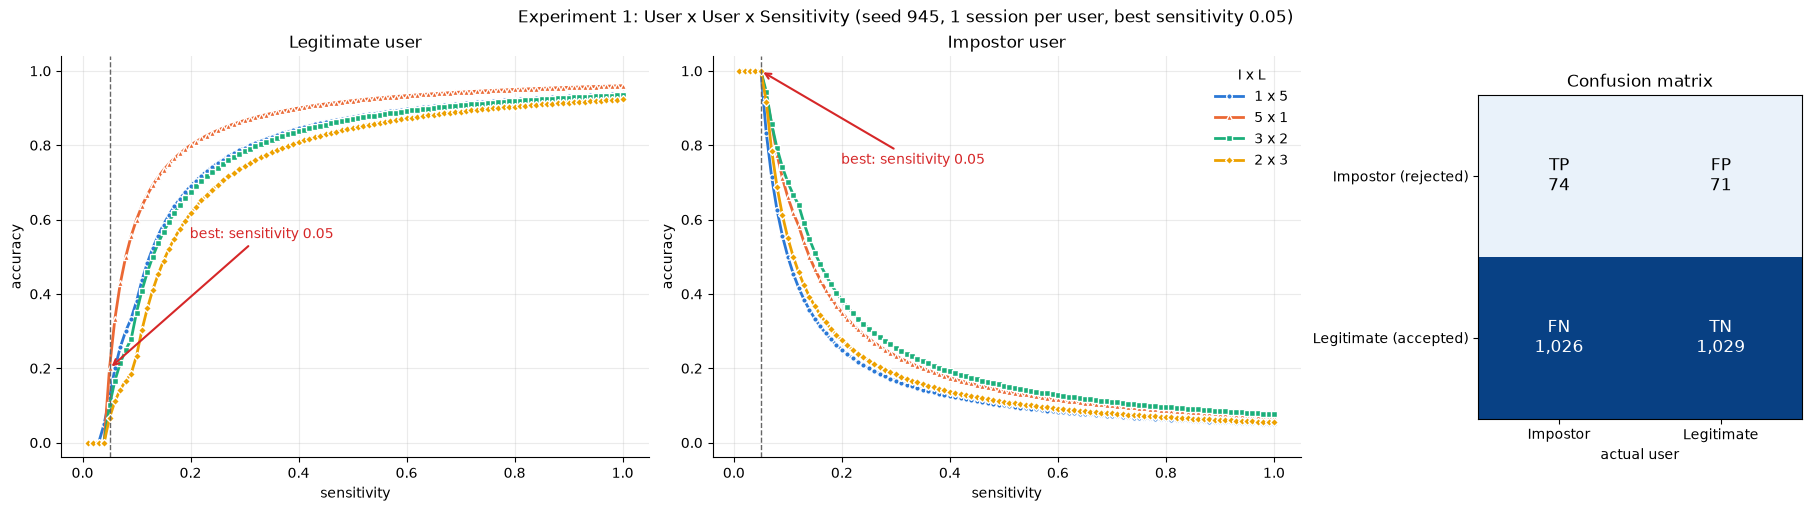

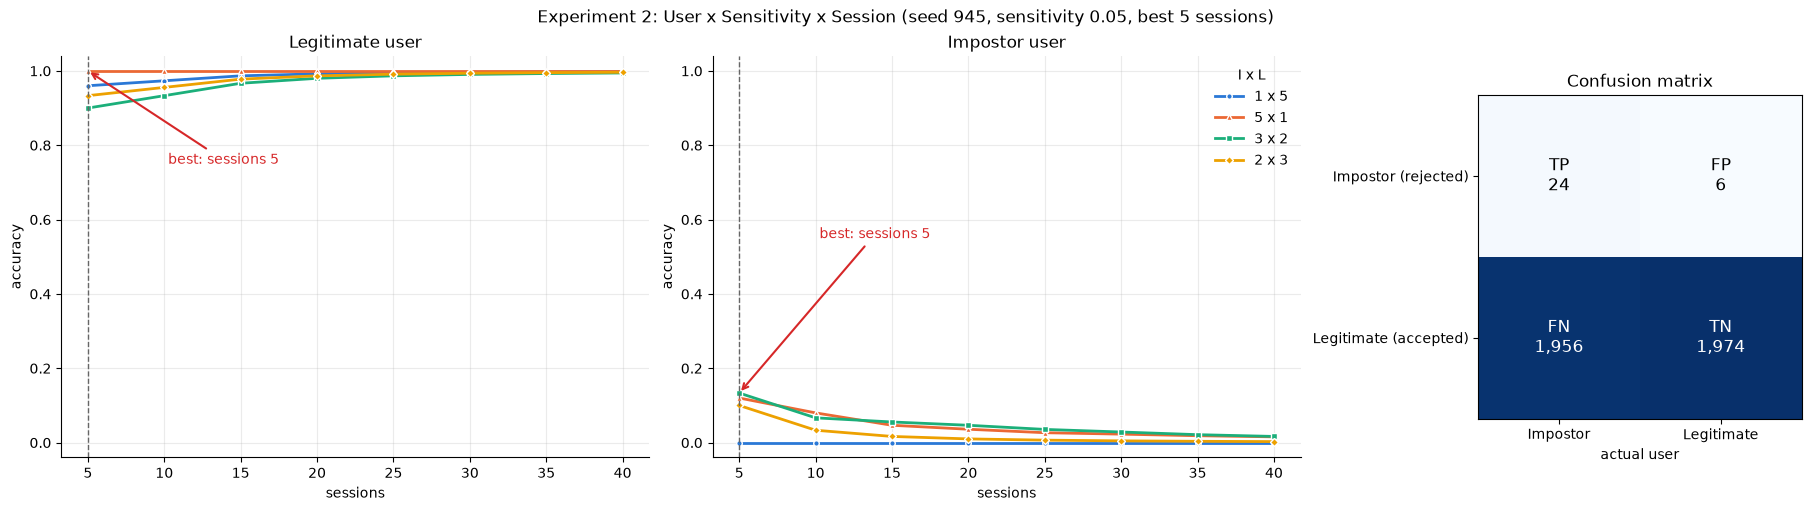

Experiment 1: best sensitivity 0.05 (accuracy 0.727, all splits)
Experiment 2: at sensitivity 0.05, best 5 sessions (accuracy 0.527, all splits)

exp1 confusion matrix (running total at the last iteration, all splits):
                       Impostor  Legitimate
Impostor (rejected)          74          71
Legitimate (accepted)      1026        1029

exp2 confusion matrix (running total at the last iteration, all splits):
                       Impostor  Legitimate
Impostor (rejected)          24           6
Legitimate (accepted)      1956        1974
Output: /home/tin/thesis-mouse-biometrics/experiment_earl/runs/19399f/experiments/ (exp1/exp2 _points.csv, _overall.csv, _confusion.csv, .png)


In [12]:
import matplotlib.pyplot as plt

COUNTS = ["TP", "FP", "FN", "TN"]
SPLIT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
SPLIT_MARKERS = ["o", "^", "s", "D"]


def split_label(legit_n: int, impostor_n: int) -> str:
    return f"{impostor_n} x {legit_n}"


def run_accuracy(config: dict) -> pd.DataFrame:
    """results/accuracy.csv of one run, simulated (accuracy only) if it does not exist yet."""
    folder = run_folder(config)
    path = folder / "results" / "accuracy.csv"
    if not path.exists():
        if not (folder / "config.yaml").exists():
            create_run(folder, config)
        legit, impostor, order = draw_users(config, config["seed"])
        write_csv(pd.DataFrame(accuracy_rows(config, folder.name, legit, impostor, order)), path)
    return pd.read_csv(path)


def confusion_counts(table: pd.DataFrame) -> dict:
    """Session counts of one run, positive = impostor."""
    legit, impostor = table[table.kind == "legitimate"], table[table.kind == "impostor"]
    return {"TP": int((impostor.tested - impostor.passed).sum()), "FP": int((legit.tested - legit.passed).sum()),
            "FN": int(impostor.passed.sum()), "TN": int(legit.passed.sum())}


def accuracy_of(counts: pd.DataFrame) -> pd.Series:
    return (counts["TP"] + counts["TN"]) / counts[COUNTS].sum(axis=1)


def experiment(points: list[tuple[float, int]], x: str) -> pd.DataFrame:
    """Per split and point (sensitivity, sessions): its counts, the running totals and their accuracies."""
    rows = []
    for sens in sorted({s for s, _ in points}):
        for legit_n, impostor_n in EXPERIMENTS["splits"]:
            for k in sorted(k for s, k in points if s == sens):
                config = {**SETTINGS, "n_legitimate": legit_n, "n_impostor": impostor_n,
                          "sensitivity": sens, "sessions_per_user": k}
                rows.append({"split": split_label(legit_n, impostor_n), "n_legitimate": legit_n,
                             "n_impostor": impostor_n, "sensitivity": sens, "sessions": k,
                             **confusion_counts(run_accuracy(config))})
        save_costs(force=True)
    order = {split_label(*s): i for i, s in enumerate(EXPERIMENTS["splits"])}
    table = pd.DataFrame(rows).sort_values(["split", x], key=lambda c: c.map(order) if c.name == "split" else c)
    table["accuracy"] = accuracy_of(table)
    running = table.groupby("split", sort=False)[COUNTS].cumsum()
    for c in COUNTS:
        table[f"total_{c}"] = running[c]

    table["total_legitimate_accuracy"] = running["TN"] / (running["TN"] + running["FP"])
    table["total_impostor_accuracy"] = running["TP"] / (running["TP"] + running["FN"])
    table["total_accuracy"] = accuracy_of(running)
    return table.reset_index(drop=True)


def overall(table: pd.DataFrame, x: str) -> tuple[pd.DataFrame, float]:
    """Per point, all splits added: counts and accuracy; the best point (ties: the lower x)."""
    per_point = table.groupby(x, as_index=False)[COUNTS].sum()
    per_point["accuracy"] = accuracy_of(per_point)
    best = per_point.sort_values(["accuracy", x], ascending=[False, True]).iloc[0][x].item()  # plain Python number, so it can go into a run's config.yaml
    per_point["best"] = per_point[x] == best
    return per_point, best


def confusion_matrix(table: pd.DataFrame) -> pd.DataFrame:
    """Running total at the last iteration, all splits added; rows = decision, columns = actual user."""
    last = table.groupby("split", sort=False).tail(1)[[f"total_{c}" for c in COUNTS]].sum()
    return pd.DataFrame([[last["total_TP"], last["total_FP"]], [last["total_FN"], last["total_TN"]]],
                        index=["Impostor (rejected)", "Legitimate (accepted)"], columns=["Impostor", "Legitimate"])


def plot_experiment(table: pd.DataFrame, matrix: pd.DataFrame, x: str, best: float, title: str, path: Path) -> None:
    """Legitimate graph, impostor graph (running totals, one line per split) and the experiment's confusion matrix.
    The best point is the dashed line, with a "best" arrow to the highest line there."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1, 0.55]}, layout="constrained")
    for ax, column, name in ((axes[0], "total_legitimate_accuracy", "Legitimate user"),
                             (axes[1], "total_impostor_accuracy", "Impostor user")):
        for i, (split, part) in enumerate(table.groupby("split", sort=False)):
            ax.plot(part[x], part[column], color=SPLIT_COLORS[i % 4], marker=SPLIT_MARKERS[i % 4], markersize=4,
                    markeredgecolor="white", linewidth=2, label=split)
        ax.axvline(best, color="0.4", linestyle="--", linewidth=1)
        at_best = table[table[x] == best]
        top = at_best[column].max()
        span = table[x].max() - table[x].min()
        unit = "sensitivity" if x == "sensitivity" else "sessions"
        ax.annotate(f"best: {unit} {best:g}", xy=(best, top),
                    xytext=(best + 0.15 * span, 0.55 if top < 0.5 else top - 0.25), fontsize=10, color="#d62728",
                    arrowprops=dict(arrowstyle="->", color="#d62728", linewidth=1.5))
        ax.set(title=name, xlabel="sensitivity" if x == "sensitivity" else "sessions", ylabel="accuracy",
               ylim=(-0.04, 1.04))
        if x == "sessions":
            ax.set_xticks(sorted(table[x].unique()))
        ax.grid(alpha=0.25)
        ax.spines[["top", "right"]].set_visible(False)
    axes[1].legend(title="I x L", frameon=False)
    values = matrix.to_numpy()
    axes[2].imshow(values / values.sum(axis=0, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for (r, c), name in zip([(0, 0), (0, 1), (1, 0), (1, 1)], COUNTS):
        share = values[r, c] / values[:, c].sum()
        axes[2].text(c, r, f"{name}\n{values[r, c]:,}", ha="center", va="center", fontsize=12,
                     color="white" if share > 0.5 else "black")
    axes[2].set_xticks([0, 1], matrix.columns)
    axes[2].set_yticks([0, 1], matrix.index)
    axes[2].set(xlabel="actual user", title="Confusion matrix")
    fig.suptitle(title)
    fig.savefig(path, dpi=130)
    plt.show()


if SECTIONS["experiments"]:
    out = group_folder() / "experiments"
    start, stop, step = EXPERIMENTS["exp1_sensitivity"]
    sensitivities = [round(start + i * step, 2) for i in range(round((stop - start) / step) + 1)]
    k1 = EXPERIMENTS["exp1_sessions"]
    exp1 = experiment([(s, k1) for s in sensitivities], "sensitivity")
    exp1_overall, best_sens = overall(exp1, "sensitivity")
    first, last, step = EXPERIMENTS["exp2_sessions"]
    exp2 = experiment([(best_sens, k) for k in range(first, last + 1, step)], "sessions")
    exp2_overall, best_k = overall(exp2, "sessions")
    for name, table, per_point in (("exp1", exp1, exp1_overall), ("exp2", exp2, exp2_overall)):
        write_csv(table.round(4), out / f"{name}_points.csv")
        write_csv(per_point.round(4), out / f"{name}_overall.csv")
    matrices = {"exp1": confusion_matrix(exp1), "exp2": confusion_matrix(exp2)}
    for name, matrix in matrices.items():
        write_csv(matrix, out / f"{name}_confusion.csv", index=True)
    plot_experiment(exp1, matrices["exp1"], "sensitivity", best_sens,
                    f"Experiment 1: User x User x Sensitivity (seed {SETTINGS['seed']}, {k1} session per user, "
                    f"best sensitivity {best_sens:g})", out / "exp1.png")
    plot_experiment(exp2, matrices["exp2"], "sessions", best_k,
                    f"Experiment 2: User x Sensitivity x Session (seed {SETTINGS['seed']}, sensitivity {best_sens:g}, "
                    f"best {best_k:g} sessions)", out / "exp2.png")
    print(f"Experiment 1: best sensitivity {best_sens:g} (accuracy "
          f"{exp1_overall.loc[exp1_overall.best, 'accuracy'].iloc[0]:.3f}, all splits)")
    print(f"Experiment 2: at sensitivity {best_sens:g}, best {best_k:g} sessions (accuracy "
          f"{exp2_overall.loc[exp2_overall.best, 'accuracy'].iloc[0]:.3f}, all splits)")
    for name, matrix in matrices.items():
        print(f"\n{name} confusion matrix (running total at the last iteration, all splits):")
        print(matrix.to_string())
    print(f"Output: {out}/ (exp1/exp2 _points.csv, _overall.csv, _confusion.csv, .png)")

## 10. Passed strokes at the best setting

Section 5 saves only counts per user (`best_rows.csv`: e.g. 18 of 25 sessions passed). This section recovers **which
sessions** those were and shows their strokes. Per split's best setting and per user of that row:

1. The sessions of the run, from the same draw and session order as the simulation (`draw_users`, `seed`): the
   **library** is the profile user's first k sessions; a **legitimate** user is tested on their own last k sessions, an
   **impostor** on their first k.
2. Each tested session is scored as in the simulation: it **passes** when at least `match_shape_ratio` of its strokes
   have a library stroke within the sensitivity. The passed sessions per user must equal `best_rows.csv`, or the
   section stops.
3. Every stroke of a passed session (cut as in the matching: a pause over `pause_gap_s`, or a click) is **trimmed** to
   its first `PASSED_STROKES["window_s"]` seconds. The pause gap only decides where a stroke ends; strokes last longer
   than it (median about 1.2 s), so the trim is what makes them short. Pass/fail is not rescored on the trimmed strokes.
4. The trimmed strokes are shifted to start at (0,0) and plotted (blue = move, orange = drag, y grows downward as on
   the screen), once with every stroke and once with each passed session's first stroke.

Writes `runs/<hash>/passed_strokes_<window>s/`:

| File | Contents |
|---|---|
| `session_results.csv` | every tested session: split, sensitivity, sessions, kind, user, profile, `position` (place in the seed's order), session, matched strokes, strokes, passed |
| `summary.csv` | per split and user: passed sessions, strokes |
| `<split>/<user>/trimmed/<session>_points_<window>s.csv` | points (`stroke`, `point`, `x`, `y`, `t_s`) within the window of each stroke |
| `<split>/<user>/first_strokes.csv` | first stroke of each passed session: points, end Δx/Δy, strokes and points per session |
| `<split>/<user>/all_strokes_<window>s.png` | every trimmed stroke of the passed sessions from (0,0) |
| `<split>/<user>/first_stroke_<window>s.png` | first stroke of each passed session from (0,0), its end labelled with the session's position |

Users logged every ~110 ms keep about 5 points per 0.5 s stroke (drawn as straight pieces); user7, user9 and user20
(~16 ms) keep about 30.

In [ ]:
import matplotlib.pyplot as plt

POINT_COLUMNS = ["stroke", "point", "x", "y", "t_s"]


def session_points(user: str, name: str, config: dict) -> tuple[pd.DataFrame, dict[int, str]]:
    """Every recorded point of a session's strokes, cut as in the matching (segment), and each stroke's kind."""
    points, kinds = [], {}
    for i, (chunk, kind) in enumerate(segment(load_session(ROOT / config["dataset_dir"] / user / name), config)):
        x, y, t = chunk.T
        points.append(pd.DataFrame({"stroke": i, "point": np.arange(len(chunk)), "x": x.astype(int), "y": y.astype(int),
                                    "t_s": t.round(3)}))
        kinds[i] = KIND_NAMES[kind]
    return (pd.concat(points, ignore_index=True) if points else pd.DataFrame(columns=POINT_COLUMNS)), kinds


def best_session_results(group: Path) -> pd.DataFrame:
    """One row per tested session of every user at every split's best setting, with its pass verdict."""
    rows = []
    for b in pd.read_csv(group / "best" / "best_rows.csv").itertuples():
        config = yaml.safe_load((group / b.run / "config.yaml").read_text())
        k = int(b.sessions)
        _, _, order = draw_users(config, config["seed"])
        start = len(order[b.user]) - k if b.kind == "legitimate" else 0  # legitimate: own last k; impostor: first k
        library = [dataset_session(b.profile, n, config) for n in order[b.profile][:k]]
        passed = 0
        for position, name in enumerate(order[b.user][start:start + k], start):
            session = dataset_session(b.user, name, config)
            hits = matched_chunks(session, library, config)
            ok = hits / max(session.n_chunks, 1) >= config["match_shape_ratio"]
            passed += ok
            rows.append({"split": f"{b.n_legitimate}x{b.n_impostor}", "sensitivity": b.sensitivity, "sessions": k,
                         "kind": b.kind, "user": b.user, "profile": b.profile, "position": position, "session": name,
                         "matched": hits, "strokes": session.n_chunks, "passed": ok, "config": config})
        if passed != b.passed:
            raise ValueError(f"{b.run} {b.user}: {passed} sessions passed here, {b.passed} in best_rows.csv")
    return pd.DataFrame(rows)


def trim(points: pd.DataFrame, window: float) -> pd.DataFrame:
    """Points within the first `window` seconds of their stroke."""
    return points[points["t_s"] - points.groupby("stroke")["t_s"].transform("first") <= window]


def plot_from_origin(strokes: list, title: str, path: Path, first_only: bool) -> None:
    """Strokes shifted to start at (0,0); for first-stroke plots, each end is marked and labelled."""
    fig, ax = plt.subplots(figsize=(8, 8))
    for g, kind, label in strokes:
        dx, dy = g["x"] - g["x"].iloc[0], g["y"] - g["y"].iloc[0]
        color = "tab:orange" if kind == "drag" else "tab:blue"
        if first_only:
            ax.plot(dx, dy, "-o", ms=2.5, lw=1.2, color=color, alpha=.8)
            ax.plot(dx.iloc[-1], dy.iloc[-1], "o", color="red", ms=4)
            ax.annotate(label, (dx.iloc[-1], dy.iloc[-1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
        else:
            ax.plot(dx, dy, color=color, lw=.5, alpha=.25)
    ax.plot(0, 0, "o", color="green", ms=6)
    ax.axhline(0, c="grey", lw=.5)
    ax.axvline(0, c="grey", lw=.5)
    ax.set_aspect("equal")
    ax.invert_yaxis()  # screen coordinates grow downward
    ax.set(title=title, xlabel="Δx (px)", ylabel="Δy (px)")
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def export_passed(rows: pd.DataFrame, out: Path, window: float) -> dict:
    """Trimmed points, first-stroke table and both plots for one user's passed sessions in one split."""
    first = rows.iloc[0]
    every, firsts, table = [], [], []
    for r in rows.itertuples():
        points, kinds = session_points(r.user, r.session, r.config)
        short = trim(points, window)
        write_csv(short, out / "trimmed" / f"{r.session}_points_{window:g}s.csv")
        groups = list(short.groupby("stroke"))
        every += [(g, kinds[s], None) for s, g in groups]
        s, g = groups[0]
        firsts.append((g, kinds[s], str(r.position)))
        table.append({"position": r.position, "session": r.session, "stroke": s, "kind": kinds[s], "points": len(g),
                      "end_dx": int(g["x"].iloc[-1] - g["x"].iloc[0]), "end_dy": int(g["y"].iloc[-1] - g["y"].iloc[0]),
                      "session_strokes": len(groups), "points_before": len(points), "points_after": len(short)})
    write_csv(pd.DataFrame(table), out / "first_strokes.csv")
    setting = f"{first.split}, {first.sensitivity}, {first.sessions}"
    plot_from_origin(every, f"{first.user}: {len(rows)} passed sessions ({setting}), {len(every):,} strokes, "
                     f"first {window:g} s, from (0,0)", out / f"all_strokes_{window:g}s.png", first_only=False)
    plot_from_origin(firsts, f"{first.user}: first stroke of each of the {len(rows)} passed sessions ({setting}), "
                     f"first {window:g} s", out / f"first_stroke_{window:g}s.png", first_only=True)
    return {"split": first.split, "kind": first.kind, "user": first.user, "passed_sessions": len(rows),
            "strokes": len(every)}


if SECTIONS["passed_strokes"]:
    group = group_folder()
    window = PASSED_STROKES["window_s"]
    if not (group / "best" / "best_rows.csv").exists():
        print(f"No {group / 'best' / 'best_rows.csv'}: run section 5 first")
    else:
        out = group / f"passed_strokes_{window:g}s"
        if out.exists():
            shutil.rmtree(out)
        results = best_session_results(group)
        write_csv(results.drop(columns="config"), out / "session_results.csv")
        passed = results[results["passed"]]
        summary = []
        for (split, user), rows in passed.groupby(["split", "user"], sort=False):
            summary.append(export_passed(rows, out / split / user, window))
            print(f"{split} {user}: {len(rows)} passed sessions, {summary[-1]['strokes']:,} strokes", flush=True)
        write_csv(pd.DataFrame(summary), out / "summary.csv")
        print(f"{len(results)} sessions tested, {len(passed)} passed")
        print(f"Output: {out}/")